# ME249 Fall 2026 - Project 2 - Task 2.3
**Genetic algorithm fit of the five-constant model  q" = n1 (Tw - Tsat)^n2 (g + n4 gen gamma)^n3 P^n5  (Eq. 1.5), 77 data points + 15 validation points**

* Cell 1: CodeP2.1F26 with modifications (i)-(ii) (red data uncommented, ND = NS = 77) + validation data.
* Cell 2: genetic algorithm (copy of the Task 2.2 program) with modifications (iii)-(vii) - see header.
* Cell 3: figure style (added).
* Cell 4: first run with the initial guesses (vii) of the statement and skeleton plot modified as in (vi).
* Cell 5: independent deterministic minimisation of the same objective (reference only).
* Cell 6: range of initial guesses / mutation amplitudes / seeds and multi-stage refinement.
* Cell 7: best fit, validation, predicted-vs-measured plots.
* Cell 8: surface plot of q"/(Tw-Tsat)^n2 versus g and gamma at P = 10 kPa.
* Cell 9: profiles showing how well each constant is determined by the data.

In [1]:
'''>>>>> start CodeP2.1F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.3 (five-constant model):
      - two data values corrected to match the Appendix listing of the project
        statement: row 0  q" 44.2 -> 44.1 W/cm2,  row 6  superheat 37.8 -> 37.5 C
      - modification (i): the red-text data lines (P = 9.5 and 7.0 kPa, gamma = 0
        and 1.71) are uncommented -> 77 data points
      - modification (ii): ND = NS = 77
      - added: the 15 validation data points of the Appendix are stored in the
        array vdata (used only to check the fitted relation, not for training)'''

# version 3 print function
from __future__ import print_function
# seed the pseudorandom number generator
from random import random
from random import seed
# seed random number generator
seed(1)

#import math and numpy packages
import math
import numpy

%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8] # for square canvas


#import copy
from copy import copy, deepcopy


#create arrays
ydata = []
lydata = []

#Parameters for Evolution Loop
#set data parameters
ND = 77       #number of data vectors in array
DI = 5        #number of data items in vector
NS = 77       #total number of DNA strands

# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
# this is an array that is essentially a list of lists

#assembling data array
#store array where rows are data vectors
#[heat flux, superheat, gravity, surface tension parameter, pressure]

ydata =     [[44.1, 32.5, 0.098, 1.79, 5.5]]    # corrected (was 44.2)
ydata.append([47.4, 33.2, 0.098, 1.79, 5.5])
ydata.append([49.4, 34.2, 0.098, 1.79, 5.5])

ydata.append([59.2, 34.8, 0.098, 1.79, 5.5])
ydata.append([67.8, 36.3, 0.098, 1.79, 5.5])
ydata.append([73.6, 37.3, 0.098, 1.79, 5.5])
ydata.append([76.3, 37.5, 0.098, 1.79, 5.5])     # corrected (was 37.8)
ydata.append([85.3, 39.2, 0.098, 1.79, 5.5])
ydata.append([96.5, 39.3, 0.098, 1.79, 5.5])
ydata.append([111., 42.3, 0.098, 1.79, 5.5])
ydata.append([124., 43.5, 0.098, 1.79, 5.5])
ydata.append([136.2, 45.4, 0.098, 1.79, 5.5])

ydata.append([143.5, 46.7, 0.098, 1.79, 5.5])
ydata.append([154.6, 47.9, 0.098, 1.79, 5.5])
ydata.append([163.1, 48.6, 0.098, 1.79, 5.5])
ydata.append([172.8, 50.9, 0.098, 1.79, 5.5])
ydata.append([184.2, 51.7, 0.098, 1.79, 5.5])
ydata.append([203.7, 56.4, 0.098, 1.79, 5.5])

ydata.append([36.7, 30.2, 9.8, 1.79, 5.5])
ydata.append([55.1, 34.1, 9.8, 1.79, 5.5])
ydata.append([67.5, 35.3, 9.8, 1.79, 5.5])
ydata.append([78.0, 37.8, 9.8, 1.79, 5.5])
ydata.append([92.0, 38.1, 9.8, 1.79, 5.5])
ydata.append([120., 44.1, 9.8, 1.79, 5.5])
ydata.append([134.3, 46.9, 9.8, 1.79, 5.5])
ydata.append([150.3, 48.5, 9.8, 1.79, 5.5])
ydata.append([167., 49.2, 9.8, 1.79, 5.5])
ydata.append([184., 52.7, 9.8, 1.79, 5.5])
ydata.append([196.5, 53.1, 9.8, 1.79, 5.5])

ydata.append([42.4, 28.0, 19.6, 1.79, 9.5])
ydata.append([48.7, 29.3, 19.6, 1.79, 9.5])
ydata.append([54.5, 29.6, 19.6, 1.79, 9.5])

ydata.append([62.1, 28.5, 19.6, 1.79, 9.5])
ydata.append([70.8, 30.5, 19.6, 1.79, 9.5])
ydata.append([73.7, 30.3, 19.6, 1.79, 9.5])
ydata.append([81.8, 30.6, 19.6, 1.79, 9.5])
ydata.append([91.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([103.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([119.1, 35.4, 19.6, 1.79, 9.5])
ydata.append([133.7, 36.8, 19.6, 1.79, 9.5])
ydata.append([139.9, 38.1, 19.6, 1.79, 9.5])
ydata.append([148.3, 39.1, 19.6, 1.79, 9.5])
ydata.append([157.0, 40.0, 19.6, 1.79, 9.5])
ydata.append([169.1, 42.2, 19.6, 1.79, 9.5])
ydata.append([179.2, 43.2, 19.6, 1.79, 9.5])
ydata.append([205.0, 46.0, 19.6, 1.79, 9.5])

ydata.append([42.4, 29.7, 19.6, 1.79, 5.5])
ydata.append([48.7, 31.0, 19.6, 1.79, 5.5])
ydata.append([54.5, 31.2, 19.6, 1.79, 5.5])
ydata.append([70.8, 32.4, 19.6, 1.79, 5.5])
ydata.append([73.7, 31.4, 19.6, 1.79, 5.5])
ydata.append([81.8, 32.5, 19.6, 1.79, 5.5])
ydata.append([91.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([103.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([119.1, 37.2, 19.6, 1.79, 5.5])
ydata.append([133.7, 38.4, 19.6, 1.79, 5.5])
ydata.append([139.9, 39.7, 19.6, 1.79, 5.5])
ydata.append([148.3, 40.9, 19.6, 1.79, 5.5])
ydata.append([157.0, 41.6, 19.6, 1.79, 5.5])
ydata.append([169.1, 43.9, 19.6, 1.79, 5.5])
ydata.append([179.2, 45.0, 19.6, 1.79, 5.5])
ydata.append([205.0, 47.9, 19.6, 1.79, 5.5])

ydata.append([77.0, 41.5, 9.8, 0.00, 7.0])
ydata.append([71.0, 40.5, 9.8, 0.00, 7.0])
ydata.append([66.0, 39.5, 9.8, 0.00, 7.0])
ydata.append([62.0, 38.5, 9.8, 0.00, 7.0])
ydata.append([42.0, 34.0, 9.8, 0.00, 7.0])
ydata.append([60.0, 37.5, 9.8, 0.00, 7.0])
ydata.append([53.0, 37.0, 9.8, 0.00, 7.0])

ydata.append([71.7, 36.4, 0.098, 1.71, 5.5])
ydata.append([81.5, 38.5, 0.098, 1.71, 5.5])
ydata.append([90.7, 39.5, 0.098, 1.71, 5.5])
ydata.append([103.3, 41.6, 0.098, 1.71, 5.5])
ydata.append([117.0, 43.1, 0.098, 1.71, 5.5])
ydata.append([138.6, 45.4, 0.098, 1.71, 5.5])
ydata.append([161.7, 47.9, 0.098, 1.71, 5.5])
ydata.append([207.5, 50.9, 0.098, 1.71, 5.5])

# validation data (Appendix, blue text) - NOT used for training
vdata =     [[50.9, 37.2, 0.098, 1.79, 5.5]]
vdata.append([75.1, 37.7, 0.098, 1.79, 5.5])
vdata.append([99.2, 39.7, 0.098, 1.79, 5.5])
vdata.append([147.7, 47.2, 0.098, 1.79, 5.5])
vdata.append([172.1, 49.7, 9.8, 1.79, 5.5])
vdata.append([49.2, 29.6, 19.6, 1.79, 9.5])
vdata.append([71.6, 30.0, 19.6, 1.79, 9.5])
vdata.append([129.8, 36.4, 19.6, 1.79, 9.5])
vdata.append([173.8, 42.8, 19.6, 1.79, 9.5])
vdata.append([68.7, 32.1, 19.6, 1.79, 5.5])
vdata.append([128.5, 38.0, 19.6, 1.79, 5.5])
vdata.append([69.0, 40.1, 9.8, 0.0, 7.0])
vdata.append([58.2, 37.1, 9.8, 0.0, 7.0])
vdata.append([100.3, 41.2, 0.098, 1.71, 5.5])
vdata.append([156.9, 47.4, 0.098, 1.71, 5.5])
NV = len(vdata)
# print the data array
print ('ydata =', ydata)
print ('number of validation points NV =', NV)
# Task 2.1(a): check of the array size and of a single array element
print ('number of rows =', len(ydata), ' ;  ydata[1][0] =', ydata[1][0], ' ;  ydata[6][1] =', ydata[6][1])


''' need deepcopy to create an array of the same size as ydata,
#   since this array is a list(rows) of lists (column entries)  '''
lydata = deepcopy(ydata)  # create array to store ln of data values


# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
#now store log values for data
for j in range(DI):
    for i in range(ND):
        lydata[i][j]=math.log(ydata[i][j]+0.000000000010)

#OK now have stored array of log values for data

#end CodeP2.1F26


ydata = [[44.1, 32.5, 0.098, 1.79, 5.5], [47.4, 33.2, 0.098, 1.79, 5.5], [49.4, 34.2, 0.098, 1.79, 5.5], [59.2, 34.8, 0.098, 1.79, 5.5], [67.8, 36.3, 0.098, 1.79, 5.5], [73.6, 37.3, 0.098, 1.79, 5.5], [76.3, 37.5, 0.098, 1.79, 5.5], [85.3, 39.2, 0.098, 1.79, 5.5], [96.5, 39.3, 0.098, 1.79, 5.5], [111.0, 42.3, 0.098, 1.79, 5.5], [124.0, 43.5, 0.098, 1.79, 5.5], [136.2, 45.4, 0.098, 1.79, 5.5], [143.5, 46.7, 0.098, 1.79, 5.5], [154.6, 47.9, 0.098, 1.79, 5.5], [163.1, 48.6, 0.098, 1.79, 5.5], [172.8, 50.9, 0.098, 1.79, 5.5], [184.2, 51.7, 0.098, 1.79, 5.5], [203.7, 56.4, 0.098, 1.79, 5.5], [36.7, 30.2, 9.8, 1.79, 5.5], [55.1, 34.1, 9.8, 1.79, 5.5], [67.5, 35.3, 9.8, 1.79, 5.5], [78.0, 37.8, 9.8, 1.79, 5.5], [92.0, 38.1, 9.8, 1.79, 5.5], [120.0, 44.1, 9.8, 1.79, 5.5], [134.3, 46.9, 9.8, 1.79, 5.5], [150.3, 48.5, 9.8, 1.79, 5.5], [167.0, 49.2, 9.8, 1.79, 5.5], [184.0, 52.7, 9.8, 1.79, 5.5], [196.5, 53.1, 9.8, 1.79, 5.5], [42.4, 28.0, 19.6, 1.79, 9.5], [48.7, 29.3, 19.6, 1.79, 9.5], [54.5, 2

In [2]:
'''>>>>> start CodeP2.2F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.3 (five-constant model, Eq. 1.5) - copy of the Task 2.2 program
    with modifications (iii)-(vii) of the project statement:
      (iii) error function Eq. (1.7) in the fitness and population-average loops
      (iv)  constants n4 and n5 included in mating/mutation
      (v)   final print-out of all five constants
      (vi)  plots of n4avg and n5avg added (see plotting cell)
      (vii) default initial guesses 0.000476, 3.028, 0.2249, 1.054, 0.217
    and, as in Task 2.2:
      - the evolution loop of the skeleton code is placed, unchanged, inside a
        function run_GA(...) so that it can be re-run for several initial guesses,
        mutation amplitudes, numbers of generations and random seeds
      - the maximum mutation amplitude (0.085 in the skeleton) is now the
        argument MUT (relative amplitude, i.e. +/- MUT*100 %)
      - both random generators (python random and numpy.random) are seeded with
        the argument rseed so that every run is reproducible
      - the history of the population-average constants and of aFerrmeanavgn is
        returned, together with the generation at which aFerrmeanavgn first drops
        below the target value (convergence-speed indicator) and the number of
        survivors nkeep of each generation (selection diagnostic)
      - BUG FIX: the skeleton line "import random" re-binds the name random to the
        module and hides the function random() imported in CodeP2.1F26, so the
        initialisation n1i+0.001*random() raises "TypeError: 'module' object is
        not callable".  The line is replaced by an explicit import of the function.'''
from random import random, seed   # (was: import random)

gen_en = 9.8   # earth-normal gravitational acceleration, m/s2

def run_GA(n1i=0.000476, n2i=3.028, n3i=0.2249, n4i=1.054, n5i=0.217, NGEN=6000, MUT=0.09,
           MFRAC=0.5, rseed=1, target=0.03, verbose=True):

    '''INITIALIZING PARAMETERS'''
    seed(rseed)                 # python random  (initial population)
    numpy.random.seed(rseed)    # numpy random   (mating / mutation)
    n = []
    ntemp = []
    gen=[0]
    n1avg = [0.0]
    n2avg = [0.0]
    n3avg = [0.0]
    n4avg = [0.0]
    n5avg = [0.0]
    meanAFerr=[0.0]
    aFerrmeanavgn=[0.0]

    # here the number of data vectors equals the number of DNA strands (or organisms)
    for k in range(NGEN-1):
        gen.append(k+1)   # generation array stores the
        meanAFerr.append(0.0)
        aFerrmeanavgn.append(0.0)
        n1avg.append(0.0)
        n2avg.append(0.0)
        n3avg.append(0.0)
        n4avg.append(0.0)
        n5avg.append(0.0)

    '''guesses for initial solution population: n0i = -1 (fixed), n1i ... n5i are arguments'''
    n0i =  -1.0

    #i initialize array where rows are dna vectors [n0i,n1i,...n5i] with random pertubations
    n =  [[-1., n1i+0.001*random(), n2i+0.1*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()]]
    for i in range(ND):
        n.append([-1., n1i+0.0001*random(), n2i+0.001*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()])

    # store also in wtemp
    ntemp = deepcopy(n)

    #define arrays of Ferr (error) functions
    Ferr =  [[0.0]]
    Ferravgn =  [[0.0]]
    aFerr =  [[0.0]]
    aFerravgn =  [[0.0]]
    for i in range(ND-1):
        Ferr.append([0.0])
        aFerr.append([0.0])
        Ferravgn.append([0.0])
        aFerravgn.append([0.0])

    aFerrmeanavgnMin=1000000000.0
    # these store the  n values for minimum population average error durng NGEN generations
    n1min = 0.0
    n2min = 0.0
    n3min = 0.0
    n4min = 0.0
    n5min = 0.0
    kmin = 0
    aFerrta = 0.0
    # these store the time averaged n values durng from generation 800 to NGEN generations
    n1ta = 0.0
    n2ta = 0.0
    n3ta = 0.0
    n4ta = 0.0
    n5ta = 0.0
    kconv = -1      # first generation with aFerrmeanavgn < target (-1 = never)
    nkeephist = []  # (added) number of survivors nkeep at each generation

    '''START OF EVOLUTION LOOP'''
    for k in range(NGEN):

        '''CALCULATING ERROR (FITNESS) - Eq. (1.3): organism i is paired with data point i'''
        for i in range(ND):

            # Eq. (1.7): -ln q" + ln n1 + n2 ln(Tw-Tsat) + n3 ln(g + n4 gen gamma) + n5 ln P
            Ferr[i] = n[i][0]*lydata[i][0] + math.log(n[i][1]) + n[i][2]*lydata[i][1]
            Ferr[i] = Ferr[i] + n[i][3]*math.log( ydata[i][2] + n[i][4]*gen_en*ydata[i][3] ) + n[i][5]*lydata[i][4]

            aFerr[i] = abs(Ferr[i])/abs(lydata[i][0])  #- absolute fractional error
        #-------------
        aFerrmean = numpy.mean(aFerr) #mean error for population for this generation
        meanAFerr[k]=aFerrmean  #store aFerrmean for this generation gen[k]=k
        aFerrmedian = numpy.median(aFerr) #median error for population for this generation

        '''SELECTION'''
        clim = MFRAC*aFerrmedian  #cut off limit is a fraction/multiplier MFRAC of median value for population
        nkeep = 0
        for j in range(NS):  # NS Ferr values, one for each solution in population
            if (aFerr[j] < clim):
                nkeep = nkeep + 1
                #ntemp[nkeep][0] = n[j][0] = -1 so it is unchanged;
                ntemp[nkeep-1][1] = n[j][1];
                ntemp[nkeep-1][2] = n[j][2];
                ntemp[nkeep-1][3] = n[j][3];
                ntemp[nkeep-1][4] = n[j][4];
                ntemp[nkeep-1][5] = n[j][5];
        #compute number to be added by mating
        nnew = NS - nkeep
        nkeephist.append(nkeep)   # (added) number of survivors, diagnostic of selection pressure

        '''MATING'''
        for j in range(nnew):
            # pick two survivors randomly
            nmate1 = numpy.random.randint(low=0, high=nkeep+1)
            nmate2 = numpy.random.randint(low=0, high=nkeep+1)

            '''here, do not change property ntemp[nkeep+j+1][0], it's always fixed at the value -1'''
            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][1] = n[nmate1][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 1, mutation added
            else:
                ntemp[nkeep+j+1][1] = n[nmate2][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][2] = n[nmate1][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 2, mutation added
            else:
                ntemp[nkeep+j+1][2] = n[nmate2][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][3] = n[nmate1][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 3, mutation added
            else:
                ntemp[nkeep+j+1][3] = n[nmate2][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][4] = n[nmate1][4]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 4, mutation added
            else:
                ntemp[nkeep+j+1][4] = n[nmate2][4]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][5] = n[nmate1][5]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 5, mutation added
            else:
                ntemp[nkeep+j+1][5] = n[nmate2][5]*(1.+MUT*2.*(0.5-numpy.random.rand()))
        #=============================================
        n = deepcopy(ntemp)   # save ntemp as n for use in next generation (next iteration)

        '''AVERAGING OVER POPULATION AND OVER TIME, FINDING MINIMUM ERROR SET OF n VALUES'''
        n1avg[k] = 0.0;
        n2avg[k] = 0.0;
        n3avg[k] = 0.0;
        n4avg[k] = 0.0;
        n5avg[k] = 0.0;
        for j in range(NS):
            n1avg[k] = n1avg[k] + n[j][1]/NS;
            n2avg[k] = n2avg[k] + n[j][2]/NS;
            n3avg[k] = n3avg[k] + n[j][3]/NS;
            n4avg[k] = n4avg[k] + n[j][4]/NS;
            n5avg[k] = n5avg[k] + n[j][5]/NS;

        ''' CALCULATING MEAN ERROR FOR POPULATION (population-average constants vs all data)'''
        for i in range(ND):
            Ferravgn[i] = -1.*lydata[i][0] + math.log(n1avg[k]) + n2avg[k]*lydata[i][1]
            Ferravgn[i] = Ferravgn[i] + n3avg[k]*math.log( ydata[i][2] + n4avg[k]*gen_en*ydata[i][3] ) + n5avg[k]*lydata[i][4]

            aFerravgn[i] = abs(Ferravgn[i])/abs(lydata[i][0])
        #-------------
        aFerrmeanavgn[k] = numpy.mean(aFerravgn)
        if (kconv < 0 and aFerrmeanavgn[k] < target):
            kconv = k

        # time average of n values in population for generations k > 800
        aFerrta = aFerrta + aFerrmeanavgn[k]/NGEN
        if (k > 800):
            n1ta = n1ta + n1avg[k]/(NGEN-800)
            n2ta = n2ta + n2avg[k]/(NGEN-800)
            n3ta = n3ta + n3avg[k]/(NGEN-800)
            n4ta = n4ta + n4avg[k]/(NGEN-800)
            n5ta = n5ta + n5avg[k]/(NGEN-800)

        # save minimum population-average error and corresponding n(i) values
        if (aFerrmeanavgn[k] < aFerrmeanavgnMin):
            aFerrmeanavgnMin = aFerrmeanavgn[k]
            n1min = n1avg[k]
            n2min = n2avg[k]
            n3min = n3avg[k]
            n4min = n4avg[k]
            n5min = n5avg[k]
            kmin = k
        '''end of evolution loop'''

    if verbose:
        print('ENDING: pop.avg n1-n5,aFerrmean:', n1avg[k], n2avg[k], n3avg[k], n4avg[k], n5avg[k], aFerrmeanavgn[k])
        print('MINUMUM:  avg n1-n5,aFerrmeanMin:', n1min, n2min, n3min, n4min, n5min, aFerrmeanavgnMin, ' at generation', kmin)
        print('TIME AVG:    avg n1-n5,aFerrmean:', n1ta, n2ta, n3ta, n4ta, n5ta, aFerrta)

    return dict(nkeephist=nkeephist, gen=gen, n1avg=n1avg, n2avg=n2avg, n3avg=n3avg, n4avg=n4avg, n5avg=n5avg,
                aFerrmeanavgn=aFerrmeanavgn,
                n1min=n1min, n2min=n2min, n3min=n3min, n4min=n4min, n5min=n5min,
                aFerrmeanavgnMin=aFerrmeanavgnMin, kmin=kmin, kconv=kconv,
                n1end=n1avg[k], n2end=n2avg[k], n3end=n3avg[k], n4end=n4avg[k], n5end=n5avg[k],
                aFerrend=aFerrmeanavgn[k], n1ta=n1ta, n2ta=n2ta, n3ta=n3ta, n4ta=n4ta, n5ta=n5ta,
                aFerrta=aFerrta)
# end CodeP2.2F26 (function definition)


In [3]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


ENDING: pop.avg n1-n5,aFerrmean: 0.0005977978243407994 2.973663051562338 0.2383352594521525 1.264015883663963 0.22061980514305884 0.03780515655707453
MINUMUM:  avg n1-n5,aFerrmeanMin: 0.0005725149126843139 2.8994130469955266 0.29596391404420047 1.2831464408414468 0.23042318073255508 0.02807869035402403  at generation 2309
TIME AVG:    avg n1-n5,aFerrmean: 0.0005845904434630606 2.943570037784134 0.22943420702324868 1.2951951681134337 0.23371338877707282 0.03378174117657572


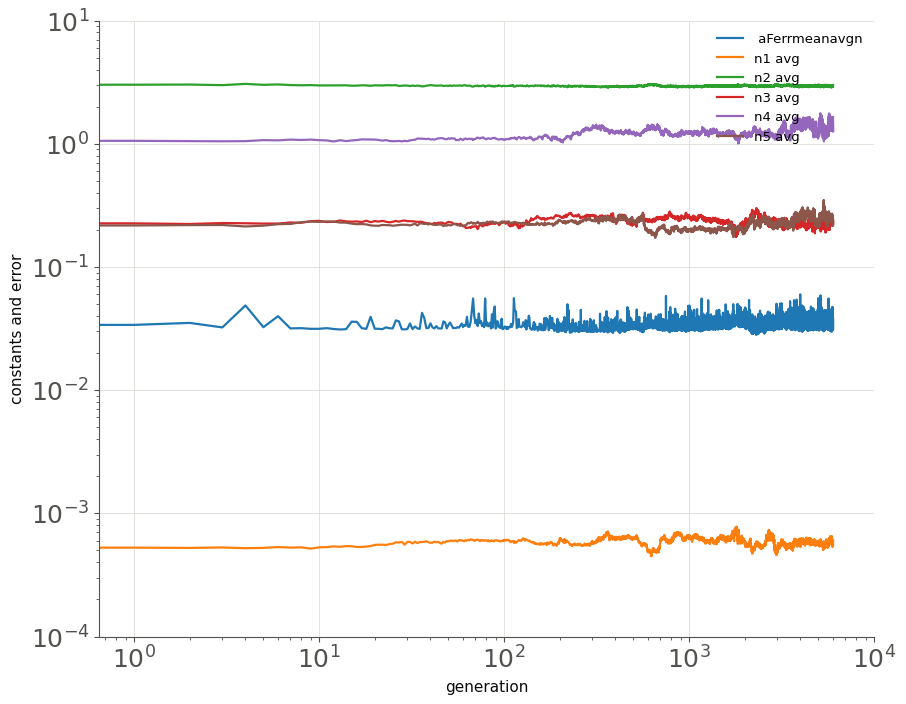

In [4]:
'''Task 2.3 - first run with the initial guesses (vii) of the project statement
   (0.000476, 3.028, 0.2249, 1.054, 0.217), mutation amplitude +/-9 % and NGEN = 6000,
   followed by the skeleton plot modified as in (vi)'''
r0 = run_GA(0.000476, 3.028, 0.2249, 1.054, 0.217, NGEN=6000, MUT=0.09, rseed=1)

plt.rcParams.update({'font.size': 18})
plt.figure(figsize=[10, 8])
plt.plot(r0['gen'], r0['aFerrmeanavgn'])
plt.plot(r0['gen'], r0['n1avg'])
plt.plot(r0['gen'], r0['n2avg'])
plt.plot(r0['gen'], r0['n3avg'])
#plt.legend(['aFerrmeanavgn', 'n1 avg', 'n2 avg', 'n3 avg'], loc='lower left')     # (vi) commented out
plt.plot(r0['gen'], r0['n4avg'])
plt.plot(r0['gen'], r0['n5avg'])
plt.legend([' aFerrmeanavgn', 'n1 avg', 'n2 avg', 'n3 avg', 'n4 avg', 'n5 avg'], loc='upper right')
plt.xlabel('generation')
plt.ylabel('constants and error')
plt.loglog()
plt.yticks([0.0001, 0.001, 0.01, 0.1, 1.0, 10])
plt.xticks([1, 10, 100, 1000, 10000])
plt.show()
plt.rcParams.update({'font.size': 11})


In [5]:
'''(added) independent check: deterministic multi-start minimisation (scipy Nelder-Mead) of the SAME
   objective, Eq. (1.8) divided by ND. Used only to judge the genetic-algorithm result.'''
from scipy.optimize import minimize
Y = numpy.array(ydata)
lq, ldT, lP = numpy.log(Y[:, 0]), numpy.log(Y[:, 1]), numpy.log(Y[:, 4])
gg, gam = Y[:, 2], Y[:, 3]

def Fmean5(n1, n2, n3, n4, n5, lq=lq, ldT=ldT, gg=gg, gam=gam, lP=lP):
    s = gg + n4 * gen_en * gam
    if n1 <= 0 or numpy.any(s <= 0):
        return 1e9
    return numpy.mean(numpy.abs(-lq + math.log(n1) + n2 * ldT + n3 * numpy.log(s) + n5 * lP) / numpy.abs(lq))

def F5x(x):                      # x = [ln n1, n2, n3, n4, n5]
    return Fmean5(math.exp(x[0]), *x[1:])

rs = numpy.random.RandomState(0)
best = None
for trial in range(40):
    x0 = [math.log(0.000476) + rs.randn(), 3.0 + 0.3 * rs.randn(), 0.3 * math.exp(0.5 * rs.randn()),
          1.0 * math.exp(0.7 * rs.randn()), 0.3 + 0.3 * rs.randn()]
    rr = minimize(F5x, x0, method='Nelder-Mead', options=dict(xatol=1e-10, fatol=1e-13, maxiter=40000, maxfev=40000))
    if best is None or rr.fun < best.fun:
        best = rr
ref5 = dict(n1=math.exp(best.x[0]), n2=best.x[1], n3=best.x[2], n4=best.x[3], n5=best.x[4], F=best.fun)
print('reference minimum: n1 = %.5e  n2 = %.4f  n3 = %.4f  n4 = %.4f  n5 = %.4f   [Ferr]mean = %.5f'
      % (ref5['n1'], ref5['n2'], ref5['n3'], ref5['n4'], ref5['n5'], ref5['F']))
print('[Ferr]mean at the initial guesses (vii) of the statement: %.5f' % Fmean5(0.000476, 3.028, 0.2249, 1.054, 0.217))


reference minimum: n1 = 1.55579e-04  n2 = 2.9771  n3 = 0.4808  n4 = 1.2586  n5 = 0.4708   [Ferr]mean = 0.02085
[Ferr]mean at the initial guesses (vii) of the statement: 0.03212


In [6]:
'''Task 2.3 - range of initial guesses (5 sets) x 2 mutation amplitudes x 5 seeds (NGEN = 6000),
   then a three-stage refinement (MUT = 0.09 -> 0.03 -> 0.01, each stage restarted from the best
   constants of the previous stage) to obtain the best fit.'''
import time
SETS23 = {'A': (0.000476, 3.028, 0.2249, 1.054, 0.217),   # initial guesses (vii) of the statement
          'B': (0.001, 3.0, 0.25, 1.0, 0.01),             # no pressure effect, pure-fluid gravity exponent
          'C': (0.0001, 3.0, 0.5, 2.0, 0.5),              # stronger gravity/Marangoni and pressure effects
          'D': (0.01, 2.5, 0.1, 0.5, 1.0),                # far
          'E': (1.0, 1.0, 1.0, 1.0, 1.0)}                 # all constants of order 1
MUTS23 = [0.09, 0.20]
SEEDS = [1, 2, 3, 4, 5]
K5 = lambda r: (r['n1min'], r['n2min'], r['n3min'], r['n4min'], r['n5min'])

def summary5(r, **kw):
    d = dict(F=r['aFerrmeanavgnMin'], n1=r['n1min'], n2=r['n2min'], n3=r['n3min'], n4=r['n4min'], n5=r['n5min'],
             kmin=r['kmin'], k030=first_below(r['aFerrmeanavgn'], 0.03), Fend=r['aFerrend'],
             nkeep_mean=float(numpy.mean(r['nkeephist'])), nkeep0=float(numpy.mean(numpy.array(r['nkeephist']) == 0)))
    d.update(kw)
    return d

t0 = time.time()
study23 = []
for name, init in SETS23.items():
    for MUT in MUTS23:
        for s in SEEDS:
            r = run_GA(*init, NGEN=6000, MUT=MUT, rseed=s, verbose=False)
            study23.append(summary5(r, set=name, init=init, MUT=MUT, MFRAC=0.5, seed=s, mode='single'))
# set E: selection with MFRAC = 1.0 (survivors = organisms with error below the median)
for s in SEEDS[:3]:
    r = run_GA(*SETS23['E'], NGEN=6000, MUT=0.09, MFRAC=1.0, rseed=s, verbose=False)
    study23.append(summary5(r, set='E', init=SETS23['E'], MUT=0.09, MFRAC=1.0, seed=s, mode='single'))
print('single-stage study: %d runs in %.0f s' % (len(study23), time.time() - t0))

print('\n%-3s %-5s %-5s | %-8s %-8s %-8s | %-5s | %-6s | %-7s' % ('set', 'MUT', 'MFRAC', 'Fbest', 'Fmedian', 'Fworst', '<0.03', 'k030', 'nkeep=0'))
table23 = []
for name in SETS23:
    for (MUT, MF) in [(m, 0.5) for m in MUTS23] + ([(0.09, 1.0)] if name == 'E' else []):
        runs = [d for d in study23 if d['set'] == name and d['MUT'] == MUT and d['MFRAC'] == MF]
        Fs = numpy.array([d['F'] for d in runs])
        b = runs[int(numpy.argmin(Fs))]
        ks = [d['k030'] for d in runs if d['k030'] >= 0]
        row = dict(set=name, init=SETS23[name], MUT=MUT, MFRAC=MF, nruns=len(runs), Fbest=float(Fs.min()), Fmed=float(numpy.median(Fs)),
                   Fworst=float(Fs.max()), nsucc=int((Fs < 0.03).sum()), k030med=float(numpy.median(ks)) if ks else -1,
                   nkeep0=float(numpy.mean([d['nkeep0'] for d in runs])), **{k: b[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5', 'seed']})
        table23.append(row)
        print('%-3s %-5s %-5s | %.5f  %.5f  %.5f | %d/%d   | %6s | %.2f   best: %.3e %.3f %.3f %.3f %.3f' % (name, MUT, MF, row['Fbest'], row['Fmed'], row['Fworst'],
              row['nsucc'], row['nruns'], '%d' % row['k030med'] if ks else 'never', row['nkeep0'], b['n1'], b['n2'], b['n3'], b['n4'], b['n5']))

# multi-stage refinement from the best single-stage run of each set (3 seeds)
t0 = time.time()
refine23 = []
for name in SETS23:
    for s in SEEDS[:3]:
        stage0 = min([d for d in study23 if d['set'] == name and d['seed'] == s], key=lambda d: d['F'])
        x = tuple(stage0[k] for k in ['n1', 'n2', 'n3', 'n4', 'n5'])
        hist_F = [stage0['F']]
        for st, MUT in enumerate([0.03, 0.01]):
            r = run_GA(*x, NGEN=6000, MUT=MUT, rseed=1000 * (st + 1) + s, verbose=False)
            if r['aFerrmeanavgnMin'] < hist_F[-1]:
                x = K5(r)
            hist_F.append(min(r['aFerrmeanavgnMin'], hist_F[-1]))
        refine23.append(dict(set=name, seed=s, start=dict(MUT=stage0['MUT'], MFRAC=stage0['MFRAC']), F_stages=hist_F,
                             F=hist_F[-1], n1=x[0], n2=x[1], n3=x[2], n4=x[3], n5=x[4]))
        print('set %s seed %d : [Ferr]mean after stages (MUT %s/0.03/0.01) = %s   n = %.4e %.4f %.4f %.4f %.4f'
              % (name, s, stage0['MUT'], ' -> '.join('%.5f' % f for f in hist_F), *x))
print('refinement: %d sequences in %.0f s' % (len(refine23), time.time() - t0))


single-stage study: 53 runs in 210 s

set MUT   MFRAC | Fbest    Fmedian  Fworst   | <0.03 | k030   | nkeep=0
A   0.09  0.5   | 0.02548  0.02739  0.02899 | 5/5   |    336 | 0.00   best: 3.997e-04 2.902 0.317 1.209 0.399
A   0.2   0.5   | 0.02463  0.02592  0.02972 | 5/5   |    358 | 0.00   best: 4.405e-04 2.735 0.246 3.925 0.671
B   0.09  0.5   | 0.03037  0.03070  0.03156 | 0/5   |  never | 0.00   best: 2.055e-03 2.649 0.327 0.936 0.011
B   0.2   0.5   | 0.02781  0.02959  0.03239 | 3/5   |   2004 | 0.00   best: 1.042e-03 2.775 0.374 1.151 0.017
C   0.09  0.5   | 0.02167  0.02203  0.02216 | 5/5   |      3 | 0.00   best: 7.877e-05 3.114 0.451 1.483 0.588
C   0.2   0.5   | 0.02170  0.02191  0.02224 | 5/5   |      2 | 0.00   best: 1.810e-04 2.969 0.415 1.471 0.496
D   0.09  0.5   | 0.03607  0.03856  0.03969 | 0/5   |  never | 0.00   best: 5.312e-03 2.325 0.145 0.756 0.496
D   0.2   0.5   | 0.03260  0.03538  0.03660 | 0/5   |  never | 0.00   best: 1.695e-03 2.664 0.174 0.793 0.370
E   0.09  

set A seed 1 : [Ferr]mean after stages (MUT 0.2/0.03/0.01) = 0.02592 -> 0.02419 -> 0.02321   n = 9.0825e-04 2.5766 0.4492 1.2895 0.3635


set A seed 2 : [Ferr]mean after stages (MUT 0.09/0.03/0.01) = 0.02548 -> 0.02400 -> 0.02341   n = 3.9171e-04 2.8582 0.3823 1.2120 0.3798


set A seed 3 : [Ferr]mean after stages (MUT 0.09/0.03/0.01) = 0.02899 -> 0.02370 -> 0.02211   n = 4.6409e-04 2.7974 0.4754 1.1922 0.2564


set B seed 1 : [Ferr]mean after stages (MUT 0.2/0.03/0.01) = 0.02781 -> 0.02692 -> 0.02508   n = 9.8947e-04 2.6887 0.5220 1.0124 0.0178


...

set D seed 2 : [Ferr]mean after stages (MUT 0.2/0.03/0.01) = 0.03538 -> 0.03483 -> 0.03455   n = 8.7037e-04 2.7583 0.0667 0.3721 0.7378


set D seed 3 : [Ferr]mean after stages (MUT 0.2/0.03/0.01) = 0.03589 -> 0.03489 -> 0.03466   n = 1.8178e-03 2.6529 0.1037 0.2016 0.5253


set E seed 1 : [Ferr]mean after stages (MUT 0.09/0.03/0.01) = 0.05337 -> 0.03351 -> 0.03302   n = 1.0383e-02 2.0380 0.4580 1.2855 0.1145


set E seed 2 : [Ferr]mean after stages (MUT 0.09/0.03/0.01) = 0.05125 -> 0.03905 -> 0.03690   n = 1.7901e-02 1.8669 0.4324 1.6370 0.1738


set E seed 3 : [Ferr]mean after stages (MUT 0.09/0.03/0.01) = 0.04968 -> 0.04097 -> 0.04089   n = 1.9162e-02 2.1094 0.1698 0.3542 0.2386
refinement: 15 sequences in 114 s


best sequence: set C (0.0001, 3.0, 0.5, 2.0, 0.5), seed 1, stage-0 MUT = 0.09, MFRAC = 0.5


--- refinement stage 1 (MUT = 0.03) ---


ENDING: pop.avg n1-n5,aFerrmean: 8.576330628306903e-05 3.102649713128122 0.4430618551159407 1.4626237669608881 0.5826721228715502 0.021328711592999906
MINUMUM:  avg n1-n5,aFerrmeanMin: 9.26245568799443e-05 3.075759620830153 0.4590941198676538 1.400100609692263 0.5764524134524295 0.021197719930162662  at generation 1148
TIME AVG:    avg n1-n5,aFerrmean: 8.43466469704734e-05 3.1027586052203473 0.44588585678297216 1.4561547627623515 0.5841901092840753 0.02256895847309106
--- refinement stage 2 (MUT = 0.01) ---


ENDING: pop.avg n1-n5,aFerrmean: 0.00011792373384802751 3.0337998230731347 0.4601369925379136 1.4127305890009534 0.5381021601759975 0.021957908580395136
MINUMUM:  avg n1-n5,aFerrmeanMin: 0.00011973020136062787 3.0215677718601066 0.4618922087596625 1.3484791418749587 0.5435187917963644 0.020972522945461276  at generation 2963
TIME AVG:    avg n1-n5,aFerrmean: 0.00011806027626763644 3.039385803845098 0.4445623731950916 1.3928941655492946 0.5433407506512306 0.021643801438513466

BEST FIT (Eq. 1.5): n1 = 1.19730e-04  n2 = 3.0216  n3 = 0.4619  n4 = 1.3485  n5 = 0.5435   [Ferr]mean,min = 0.02097
reference minimum : n1 = 1.55579e-04  n2 = 2.9771  n3 = 0.4808  n4 = 1.2586  n5 = 0.4708   [Ferr]mean     = 0.02085
validation data: [Ferr]mean = 0.02566 (15 points)
train: rms deviation 17.20 W/cm2, rms fractional deviation 0.1233, mean |dev| 0.0937, within +/-10 %: 0.58
val  : rms deviation 14.97 W/cm2, rms fractional deviation 0.1413, mean |dev| 0.1086, within +/-10 %: 0.53
g = 0.098  gamma = 1.79

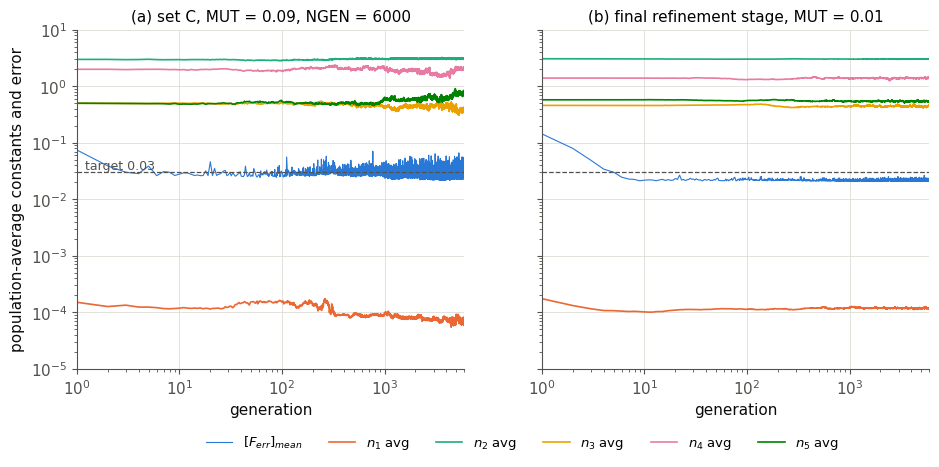

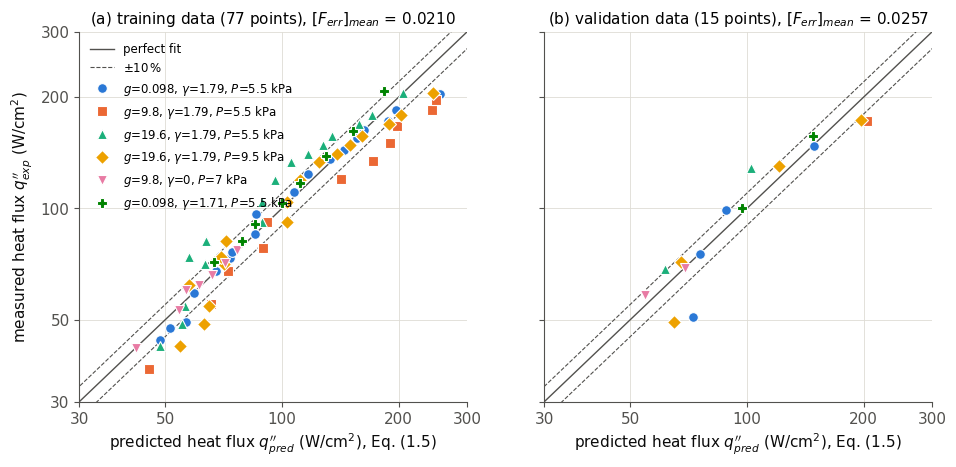

In [7]:
'''Task 2.3 - best fit: the refinement sequence with the lowest error is replayed (same seeds) and its
   constants are used for the tables, the predicted-vs-measured plots and the validation check.'''
bestseq = min(refine23, key=lambda d: d['F'])
s = bestseq['seed']
st0 = min([d for d in study23 if d['set'] == bestseq['set'] and d['seed'] == s], key=lambda d: d['F'])
print('best sequence: set %s %s, seed %d, stage-0 MUT = %s, MFRAC = %s' % (bestseq['set'], SETS23[bestseq['set']], s, st0['MUT'], st0['MFRAC']))
stages = [run_GA(*SETS23[bestseq['set']], NGEN=6000, MUT=st0['MUT'], MFRAC=st0['MFRAC'], rseed=s, verbose=False)]
x = K5(stages[0]); Fx = stages[0]['aFerrmeanavgnMin']
for st, MUT in enumerate([0.03, 0.01]):
    print('--- refinement stage %d (MUT = %.2f) ---' % (st + 1, MUT))
    r = run_GA(*x, NGEN=6000, MUT=MUT, rseed=1000 * (st + 1) + s)
    stages.append(r)
    if r['aFerrmeanavgnMin'] < Fx:
        x, Fx = K5(r), r['aFerrmeanavgnMin']
n1min, n2min, n3min, n4min, n5min = x
best23 = dict(n1=n1min, n2=n2min, n3=n3min, n4=n4min, n5=n5min, F=Fx)
print('\nBEST FIT (Eq. 1.5): n1 = %.5e  n2 = %.4f  n3 = %.4f  n4 = %.4f  n5 = %.4f   [Ferr]mean,min = %.5f' % (*x, Fx))
print('reference minimum : n1 = %.5e  n2 = %.4f  n3 = %.4f  n4 = %.4f  n5 = %.4f   [Ferr]mean     = %.5f'
      % (ref5['n1'], ref5['n2'], ref5['n3'], ref5['n4'], ref5['n5'], ref5['F']))

# validation data (15 points of the Appendix, never used in the fit)
V = numpy.array(vdata)
Fval = Fmean5(*x, lq=numpy.log(V[:, 0]), ldT=numpy.log(V[:, 1]), gg=V[:, 2], gam=V[:, 3], lP=numpy.log(V[:, 4]))
best23['Fval'] = Fval
print('validation data: [Ferr]mean = %.5f (15 points)' % Fval)

def q5(x, row):
    n1, n2, n3, n4, n5 = x
    return n1 * row[1]**n2 * (row[2] + n4 * gen_en * row[3])**n3 * row[4]**n5

stats23 = {}
for lab, D in [('train', ydata), ('val', vdata)]:
    qp = numpy.array([q5(x, row) for row in D]); qd = numpy.array([row[0] for row in D])
    dev = (qd - qp) / qp
    stats23[lab] = dict(rms_abs=float(numpy.sqrt(numpy.mean((qd - qp)**2))), rms_rel=float(numpy.sqrt(numpy.mean(dev**2))),
                        mean_abs_rel=float(numpy.mean(numpy.abs(dev))), within10=float(numpy.mean(numpy.abs(dev) <= 0.1)))
    print('%-5s: rms deviation %.2f W/cm2, rms fractional deviation %.4f, mean |dev| %.4f, within +/-10 %%: %.2f'
          % (lab, stats23[lab]['rms_abs'], stats23[lab]['rms_rel'], stats23[lab]['mean_abs_rel'], stats23[lab]['within10']))

# deviation per test condition: is what remains random, or still systematic?
cond = [(0.098, 1.79, 5.5), (9.8, 1.79, 5.5), (19.6, 1.79, 5.5), (19.6, 1.79, 9.5), (9.8, 0.0, 7.0), (0.098, 1.71, 5.5)]
bias23 = []
for cd in cond:
    rows = [row for row in ydata if (row[2], row[3], row[4]) == cd]
    dev = numpy.array([(row[0] - q5(x, row)) / q5(x, row) for row in rows])
    bias23.append(dict(g=cd[0], gamma=cd[1], P=cd[2], n=len(rows), mean_dev=float(dev.mean()), rms_dev=float(numpy.sqrt(numpy.mean(dev**2)))))
    print('g = %5.3f  gamma = %4.2f  P = %3.1f kPa (%2d points): mean deviation %+.3f   rms deviation %.3f'
          % (cd[0], cd[1], cd[2], len(rows), dev.mean(), numpy.sqrt(numpy.mean(dev**2))))

# evolution plots: (a) main GA run, (b) last refinement stage
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a, r, title in [(axs[0], stages[0], '(a) set %s, MUT = %s, NGEN = 6000' % (bestseq['set'], st0['MUT'])),
                    (axs[1], stages[-1], '(b) final refinement stage, MUT = 0.01')]:
    g = numpy.arange(1, len(r['gen']) + 1)
    a.plot(g, r['aFerrmeanavgn'], color=C[0], lw=0.8, label=r'$[F_{err}]_{mean}$')
    for c, (k, lab) in enumerate([('n1avg', '$n_1$'), ('n2avg', '$n_2$'), ('n3avg', '$n_3$'), ('n4avg', '$n_4$'), ('n5avg', '$n_5$')]):
        a.plot(g, r[k], color=C[c + 1], lw=1.2, label=lab + ' avg')
    a.axhline(0.03, color=INK2, ls='--', lw=0.9)
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlim(1, len(g)); a.set_ylim(1e-5, 10)
    a.set_xlabel('generation'); a.set_title(title)
axs[0].set_ylabel('population-average constants and error')
axs[0].text(1.2, 0.033, 'target 0.03', color=INK2, fontsize=9)
axs[1].legend(loc='upper center', bbox_to_anchor=(-0.05, -0.16), ncol=6)
savefig('t23_evolution')

# predicted vs measured: training (77) and validation (15) points, one symbol per test condition
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
xx = numpy.array([10, 1000])
for a, D, title in [(axs[0], ydata, '(a) training data (77 points), $[F_{err}]_{mean}$ = %.4f' % Fx),
                    (axs[1], vdata, '(b) validation data (15 points), $[F_{err}]_{mean}$ = %.4f' % Fval)]:
    a.plot(xx, xx, '-', color=INK2, lw=1, label='perfect fit')
    a.plot(xx, 1.1 * xx, '--', color=INK2, lw=0.8, label=r'$\pm 10\,\%$')
    a.plot(xx, 0.9 * xx, '--', color=INK2, lw=0.8)
    for c, cd in enumerate(cond):
        rows = [row for row in D if (row[2], row[3], row[4]) == cd]
        if rows:
            a.loglog([q5(x, row) for row in rows], [row[0] for row in rows], MK[c], color=C[c], ms=7, mec='white', mew=0.8,
                     label=r'$g$=%g, $\gamma$=%g, $P$=%g kPa' % cd)
    a.set_xlim(30, 300); a.set_ylim(30, 300)
    plain_log_ticks(a, [30, 50, 100, 200, 300], [30, 50, 100, 200, 300])
    a.set_xlabel(r'predicted heat flux $q^{\prime\prime}_{pred}$ (W/cm$^2$), Eq. (1.5)')
    a.set_title(title)
axs[0].set_ylabel(r'measured heat flux $q^{\prime\prime}_{exp}$ (W/cm$^2$)')
axs[0].legend(loc='upper left', fontsize=8.5)
savefig('t23_parity')

json.dump(dict(best=best23, ref=ref5, base=dict(F=r0['aFerrmeanavgnMin'], n1=r0['n1min'], n2=r0['n2min'], n3=r0['n3min'],
               n4=r0['n4min'], n5=r0['n5min'], kmin=r0['kmin'], k030=first_below(r0['aFerrmeanavgn'], 0.03),
               n1end=r0['n1end'], n2end=r0['n2end'], n3end=r0['n3end'], n4end=r0['n4end'], n5end=r0['n5end'],
               Fend=r0['aFerrend'], n1ta=r0['n1ta'], n2ta=r0['n2ta'], n3ta=r0['n3ta'], n4ta=r0['n4ta'], n5ta=r0['n5ta'], Fta=r0['aFerrta']),
               bestseq=bestseq, stats=stats23, bias=bias23, table=table23, refine=refine23, runs=study23,
               F_init_vii=Fmean5(0.000476, 3.028, 0.2249, 1.054, 0.217)),
          open(RESDIR + 'task23.json', 'w'), indent=1)


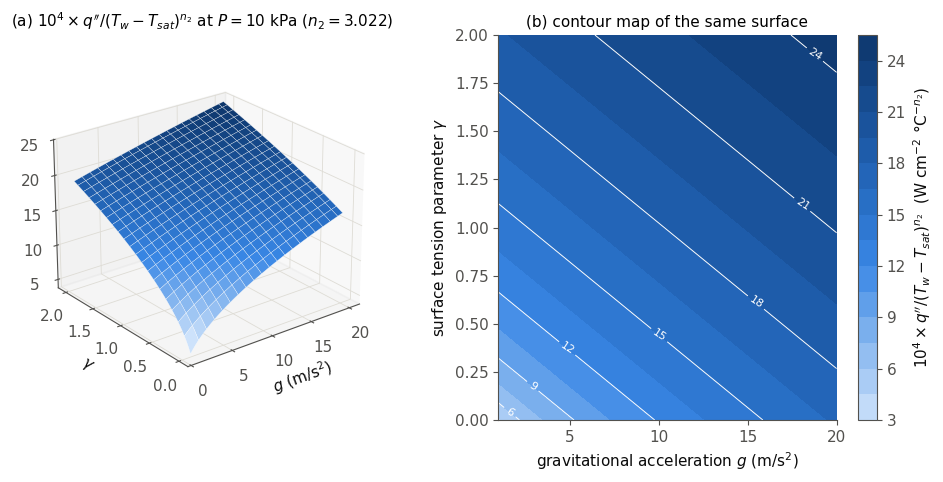

g =   1.0  gamma = 0.00 :  q"/(Tw-Tsat)^n2 = 4.1853e-04
g =  20.0  gamma = 0.00 :  q"/(Tw-Tsat)^n2 = 1.6698e-03
g =   1.0  gamma = 2.00 :  q"/(Tw-Tsat)^n2 = 1.9321e-03
g =  20.0  gamma = 2.00 :  q"/(Tw-Tsat)^n2 = 2.4638e-03
g =   1.0  gamma = 1.79 :  q"/(Tw-Tsat)^n2 = 1.8392e-03
g =   9.8  gamma = 1.79 :  q"/(Tw-Tsat)^n2 = 2.1177e-03
ratio max/min over the plotted domain: 5.89


In [8]:
'''Task 2.3 - surface plot of q"/(Tw-Tsat)^n2 = n1 (g + n4 gen gamma)^n3 P^n5 versus g and gamma
   for 1 < g < 20 m/s2 and 0 < gamma < 2 at P = 10 kPa (best-fit constants)'''
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401  (registers the 3d projection)
Pplot = 10.0
gs = numpy.linspace(1.0, 20.0, 60)
gms = numpy.linspace(0.0, 2.0, 60)
G, GM = numpy.meshgrid(gs, gms)
Z = n1min * (G + n4min * gen_en * GM)**n3min * Pplot**n5min       # W/cm2 per (deg C)^n2

fig = plt.figure(figsize=(12, 5.0))
ax = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax.plot_surface(G, GM, Z * 1e4, cmap=BLUES, linewidth=0.2, edgecolor='white', antialiased=True, rstride=3, cstride=3)
ax.set_xlabel(r'$g$ (m/s$^2$)', labelpad=6); ax.set_ylabel(r'$\gamma$', labelpad=6)
ax.view_init(elev=24, azim=-128)
ax.set_box_aspect(None, zoom=0.88)
ax.set_title(r'(a) $10^4\times q^{\prime\prime}/(T_w-T_{sat})^{n_2}$ at $P = 10$ kPa ($n_2 = %.3f$)' % n2min)
a2 = fig.add_subplot(1, 2, 2)
cs = a2.contourf(G, GM, Z * 1e4, levels=14, cmap=BLUES)
cl = a2.contour(G, GM, Z * 1e4, levels=cs.levels[::2], colors='white', linewidths=0.7)
a2.clabel(cl, fmt='%.0f', fontsize=8)
cb = fig.colorbar(cs, ax=a2)
cb.set_label(r'$10^4\times q^{\prime\prime}/(T_w-T_{sat})^{n_2}$  (W cm$^{-2}$ °C$^{-n_2}$)')
a2.set_xlabel(r'gravitational acceleration $g$ (m/s$^2$)'); a2.set_ylabel(r'surface tension parameter $\gamma$')
a2.set_title('(b) contour map of the same surface')
a2.grid(False)
savefig('t23_surface')

# numbers quoted in the report
for gv, gmv in [(1, 0), (20, 0), (1, 2), (20, 2), (1, 1.79), (9.8, 1.79)]:
    print('g = %5.1f  gamma = %4.2f :  q"/(Tw-Tsat)^n2 = %.4e' % (gv, gmv, n1min * (gv + n4min * gen_en * gmv)**n3min * Pplot**n5min))
print('ratio max/min over the plotted domain: %.2f' % (Z.max() / Z.min()))


n2 2.6:0.02294 2.7:0.02217 2.8:0.02156 2.9:0.02105 3:0.02086 3.1:0.02110 3.2:0.02151 3.3:0.02206 3.4:0.02286


n3 0.1:0.02571 0.2:0.02492 0.3:0.02324 0.4:0.02157 0.5:0.02098 0.6:0.02353 0.7:0.02809 0.8:0.03286 0.9:0.03776 1:0.04279


n4 0.4:0.03088 0.6:0.02832 0.8:0.02506 1:0.02233 1.25:0.02087 1.5:0.02121 2:0.02226 3:0.02341 4:0.02404


n5 -0.2:0.02764 -0.05:0.02483 0.1:0.02293 0.25:0.02167 0.4:0.02103 0.55:0.02096 0.7:0.02198 0.85:0.02340 1:0.02572


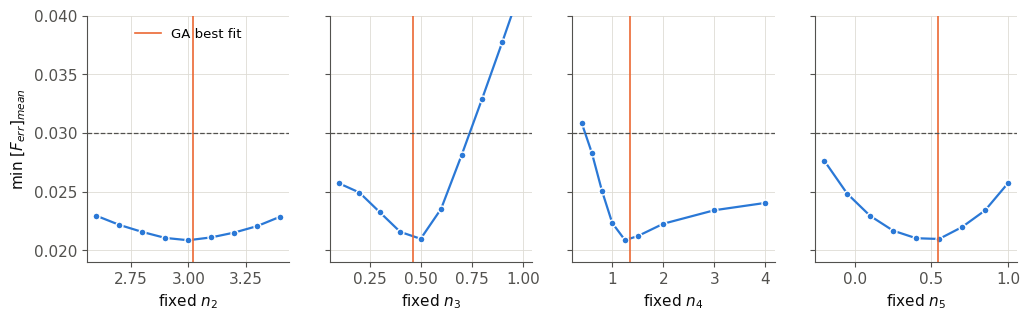

In [9]:
'''(added) Task 2.3 - how well is each constant determined by the data?  Profile of the minimum
   achievable [Ferr]mean when one constant is fixed and the four others are re-optimised
   (deterministic minimisation of the same objective).  A flat profile = weakly determined constant.'''
prof = {}
specs = [(1, 'n2', numpy.linspace(2.6, 3.4, 9)), (2, 'n3', numpy.linspace(0.1, 1.0, 10)),
         (3, 'n4', numpy.array([0.4, 0.6, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0])), (4, 'n5', numpy.linspace(-0.2, 1.0, 9))]
xref = numpy.array([math.log(ref5['n1']), ref5['n2'], ref5['n3'], ref5['n4'], ref5['n5']])
for idx, name, vals in specs:
    out = []
    order = numpy.argsort(numpy.abs(vals - xref[idx]))      # start next to the minimum and move outwards
    sol = {}
    for j in order:
        v = vals[j]
        starts = [numpy.delete(xref, idx) * (1 + 0.05 * rs.randn(4)) for trial in range(4)]
        near = [sol[jj] for jj in sol if abs(jj - j) == 1]      # warm start from the neighbouring point(s)
        bestp = None
        for y0 in near + starts:
            rr = minimize(lambda y: F5x(numpy.insert(y, idx, v)), y0, method='Nelder-Mead',
                          options=dict(xatol=1e-9, fatol=1e-12, maxiter=20000, maxfev=20000))
            if bestp is None or rr.fun < bestp.fun:
                bestp = rr
        sol[j] = bestp.x
        out.append((j, bestp.fun))
    out = [fv for jj, fv in sorted(out)]
    prof[name] = (vals, numpy.array(out))
    print(name, ' '.join('%.3g:%.5f' % (v, f) for v, f in zip(vals, out)))

fig, axs = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for a, (idx, name, vals) in zip(axs, specs):
    v, f = prof[name]
    a.plot(v, f, '-o', color=C[0], ms=5, mec='white')
    a.axvline(best23[name], color=C[1], lw=1.2, label='GA best fit')
    a.axhline(0.03, color=INK2, ls='--', lw=0.9)
    a.set_xlabel('fixed $n_%s$' % name[1])
axs[0].set_ylabel(r'min $[F_{err}]_{mean}$')
axs[0].set_ylim(0.019, 0.04)
axs[0].legend(loc='upper center')
savefig('t23_profiles')
res = json.load(open(RESDIR + 'task23.json'))
res['profiles'] = {k: [list(map(float, v[0])), list(map(float, v[1]))] for k, v in prof.items()}
json.dump(res, open(RESDIR + 'task23.json', 'w'), indent=1)
